In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings

sns.set_theme(style="whitegrid")
os.makedirs("images", exist_ok=True)

# 1 - Loading the data

In [2]:
if os.path.exists("oes_2023.pkl"):
    df = pd.read_pickle("oes_2023.pkl")
else:
    df = pd.read_excel("all_data_M_2023.xlsx", sheet_name="All May 2023 data", dtype=str)
    df.to_pickle("oes_2023.pkl")

print(df.shape)
df.head()

(413327, 32)


,AREA,AREA_TITLE,AREA_TYPE,PRIM_STATE,NAICS,NAICS_TITLE,I_GROUP,OWN_CODE,OCC_CODE,OCC_TITLE,...,H_MEDIAN,H_PCT75,H_PCT90,A_PCT10,A_PCT25,A_MEDIAN,A_PCT75,A_PCT90,ANNUAL,HOURLY
0,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,00-0000,All Occupations,...,23.11,37.01,58.4,29050,35660,48060,76980,121470,NaN,NaN
1,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-0000,Management Occupations,...,56.19,81.29,111.36,54550,78330,116880,169090,231620,NaN,NaN
2,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1000,Top Executives,...,49.74,79.57,#,46400,66170,103460,165500,#,NaN,NaN
3,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1010,Chief Executives,...,99.37,#,#,80000,130840,206680,#,#,NaN,NaN
4,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1011,Chief Executives,...,99.37,#,#,80000,130840,206680,#,#,NaN,NaN


# 2 - Cleaning and selecting occupations

In this case '#" means that the wage is higher than 239200 so I will be swapping them. Also, * means that the value is not avaiable.

In [3]:
numeric_cols = ["TOT_EMP", "LOC_QUOTIENT", "A_MEAN", "A_PCT10", "A_PCT25", "A_MEDIAN", "A_PCT75", "A_PCT90"]

for col in numeric_cols:
    df[col] = df[col].replace("#", "239200")
    df[col] = pd.to_numeric(df[col], errors="coerce")

I chose 6 occupations and separated them in 2 groups 

In [4]:
occupations = {
    "15-1252": ["Software Developers",          "Development"],
    "15-1251": ["Computer Programmers",         "Development"],
    "15-1254": ["Web Developers",               "Development"],
    "15-1241": ["Network Architects",           "Networking"],
    "15-1244": ["Network & Systems Admins",     "Networking"],
    "15-1231": ["Network Support Specialists",  "Networking"],
}
colours = {"Development": "tab:green", "Networking": "tab:blue"}
usa = df[(df["AREA_TYPE"] == "1") & (df["I_GROUP"] == "cross-industry")]
jobs = usa[usa["OCC_CODE"].isin(occupations.keys())].copy()
jobs["NAME"] = jobs["OCC_CODE"].map(lambda c: occupations[c][0])
jobs["FIELD"] = jobs["OCC_CODE"].map(lambda c: occupations[c][1])
jobs[["OCC_CODE", "NAME", "FIELD", "TOT_EMP", "A_MEDIAN"]].sort_values("TOT_EMP", ascending=False)

,OCC_CODE,NAME,FIELD,TOT_EMP,A_MEDIAN
149,15-1252,Software Developers,Development,1656880.0,132270.0
146,15-1244,Network & Systems Admins,Networking,323020.0,95360.0
143,15-1241,Network Architects,Networking,174100.0,129840.0
140,15-1231,Network Support Specialists,Networking,158720.0,71530.0
148,15-1251,Computer Programmers,Development,120370.0,99700.0
151,15-1254,Web Developers,Development,85350.0,84960.0


## 3 - Bar chart

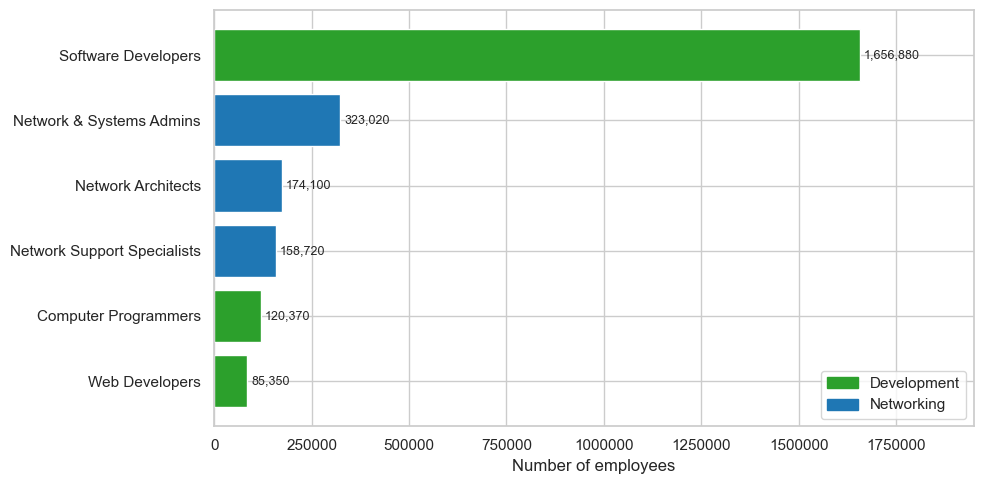

In [25]:
data = jobs.sort_values("TOT_EMP")
plt.figure(figsize=(10, 5))
plt.barh(data["NAME"], data["TOT_EMP"], color=data["FIELD"].map(colours))
plt.xlabel("Number of employees")
for i, value in enumerate(data["TOT_EMP"]):
    plt.text(value + 10000, i, f"{value:,.0f}", va="center", fontsize=9)
plt.xlim(0, 1950000)
plt.ticklabel_format(style="plain", axis="x")   
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in colours.values()]
plt.legend(handles, colours.keys(), loc="lower right")
plt.tight_layout()
plt.show()

Now, in order to compare the occupations I am using the bar chart because it makes very easy to compare each occupation and 
I can clearly separate the groups by adding different colours to them.

We can clearly see that the Software Devs are the biggest group. There are more employees as Software Developers than all the sum of employees
doing other role and about five times bigger than the second group Network & Systems Admin or almost 3 times bigger than the Networking groups.
Web devs are the smallest number with 85.350 just below Computer Programmers with 120.370 employees.


# 4 - Pie Chart

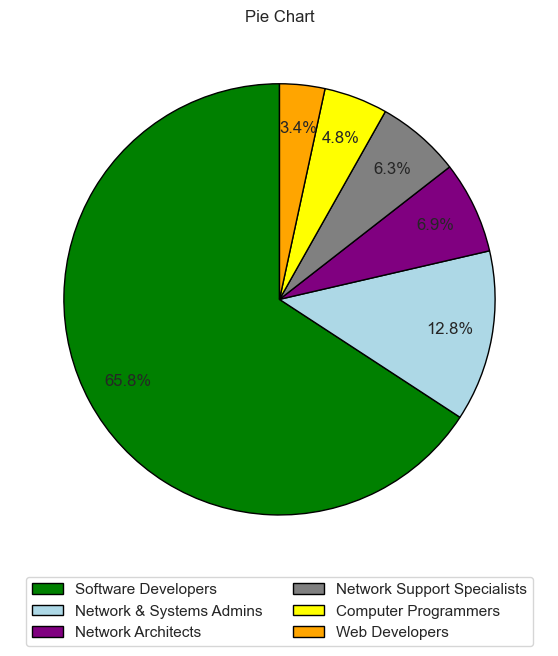

In [49]:
data = jobs.sort_values("TOT_EMP", ascending=False)
shades = {"Software Developers": "green", "Computer Programmers": "yellow", "Web Developers": "orange", "Network & Systems Admins": "lightblue", "Network Architects": "toam", "Network Support Specialists": "gray"}
plt.figure(figsize=(7, 7))
plt.pie(data["TOT_EMP"], autopct="%1.1f%%", startangle=90, pctdistance=0.8,
colors=data["NAME"].map(shades), wedgeprops={"edgecolor": "black"})
plt.legend(data["NAME"], loc="upper center", bbox_to_anchor=(0.5, 0), ncol=2)
plt.title("Pie Chart")
plt.show()

Now with the pie chart we can see exactly what proportion of the whole each job occupies. With the percentages we have a better understanding of this and make it much easier to compare with different roles. 

We had already notice in the bar chart that Software Developers have the largest number of employees, however, now with this chart we see that Software Developers represents 65.8% of all these jobs. Again, the second largest group is Network & Sys Admins with 12.8% followed by Network Architects and Network Support Specialist both with very similar percentages 6.9% and 6.3%. Computer programmers with 4.8% and Web Devs being the
smallest with 3.4%.
